# Adversarial Search: Solving Tic-Tac-Toe with Monte Carlo Tree Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. __Monte Carlo Search:__ Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* We enhance Pure Monte Carlo Search by using the upper confidence bound (UCB1) selection policy. That is, we use UCB1 to determine for which action to perform the next playout. This will allow the algorithm to focus on actions here it needs to collect more information. Note that complete Upper Confidence Bounds applied to Trees (UCT) creates a tree and the expand step in the code needs to be added. The tree branch for the chosen move is preserved and used for future moves.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py). 

In [15]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [16]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# Monte Carlo Search with Upper Confidence Bound

See AIMA page 163. 

We enhance pure Monte Carlo Search by using UCB1 as a __selection policy__. This can be seen as a 
restricted version of UTC: 
* Only build a tree of depth 1 and use the UBC1 selection policy.
* Use a random playout policy.


__Note on the playout policy:__ We use here a random playout policy, which ends up creating just a randomized search that works fine for this toy problem. For real applications you need to extend the code with a good __playout policy__ (e.g., manually created heuristics or a neural [network learned by self-play using reinforcement learning](https://towardsdatascience.com/how-to-teach-an-ai-to-play-games-deep-reinforcement-learning-28f9b920440a)).

## Simulate playouts

In [17]:
import numpy as np

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: 
            return u
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)


board = empty_board()
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))

1
1
1


## Upper Confidence Bound Applied to Trees (Restricted to Depth 1)

In [18]:
import pandas as pd
import math

DEBUG = 1

def UCT_depth1(board, N = 100, player = 'x'):
    """Upper Confidence bound applied to Trees for limited tree depth of 1. 
    Simulation budget is N playouts."""
    global DEBUG
    
    C = math.sqrt(2) # tradeoff constant
    
    # the tree is 1 action deep
    acts = actions(board)
    
    u = [0] * len(acts) # total utility through actions
    n = [0] * len(acts) # number of playouts through actions
    n_parent = 0 # total playouts so far (i.e., number of playouts through parent)
    
    # make sure we try each action once
    UCB1 = [+math.inf] * len(acts) 
    
    for i in range(N):

        # Select
        action_id = UCB1.index(max(UCB1))
    
        # Expand
        # UTC would expand the tree. We keep the tree at depth 1, essentially performing
        # Pure Monte Carlo search with an added UCB1 selection policy. 
        
        # Simulate
        p = playout(board, acts[action_id], player = player)
    
        # Back-Propagate (i.e., update counts and UCB1)
        u[action_id] += p
        n[action_id] += 1
        n_parent += 1
        
        for action_id in range(len(acts)):
            if n[action_id] > 0:
                UCB1[action_id] = u[action_id] / n[action_id] + C * math.sqrt(math.log(n_parent) / n[action_id])
    
    # return action with largest number of playouts 
    action = acts[n.index(max(n))]
    
    if DEBUG >= 1: 
        print(pd.DataFrame({'action':acts, 
                            'total utility':u, 
                            '# of playouts':n, 
                            'UCB1':UCB1}))
        print()
        print(f"Best action: {action}")
    
    
    return action

In [19]:
board = empty_board()
display(board)

%timeit -n 1 -r 1 UCT_depth1(board, N = 1000)

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

   action  total utility  # of playouts      UCB1
0       0              5             47  0.648552
1       1             31            107  0.649048
2       2             22             90  0.636242
3       3             26             97  0.645438
4       4            104            226  0.707423
5       5             30            105  0.648449
6       6             64            174  0.649595
7       7             19             82  0.642173
8       8             15             72  0.646377

Best action: 4
390 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


## Some Tests

### x is about to win (play 8)

Board:


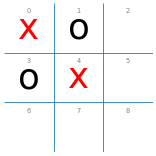


   action  total utility  # of playouts      UCB1
0       2             21             23  1.545854
1       5              7             11  1.551407
2       6             14             18  1.493100
3       7             13             17  1.500766
4       8             31             31  1.545076

Best action: 8
16.1 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [20]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board)

### o is about to win

Board:


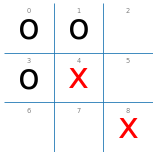


   action  total utility  # of playouts      UCB1
0       2            -18            442  0.136072
1       5            -17             33  0.131882
2       6            -14            514  0.136709
3       7            -11             11  0.120694

Best action: 6
109 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [21]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board, N = 1000)

### x can draw if it chooses 7

Board:


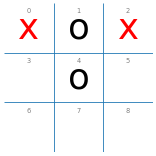


   action  total utility  # of playouts      UCB1
0       3            -10             80  0.290565
1       5             -7            109  0.291796
2       6            -12             30  0.278614
3       7            121            740  0.300150
4       8            -12             41  0.287803

Best action: 7
238 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [22]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board, N = 1000)

### Empty board: Only a draw an be guaranteed

Board:


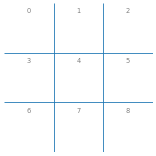


   action  total utility  # of playouts      UCB1
0       0              1             10  1.059705
1       1              3             12  1.126087
2       2             -2              4  1.017427
3       3              1              9  1.122729
4       4              7             19  1.064664
5       5              2             12  1.042754
6       6              9             20  1.128614
7       7              0              8  1.072983
8       8             -1              6  1.072307

Best action: 6
36 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)
   action  total utility  # of playouts      UCB1
0       0             91            270  0.588215
1       1             23            115  0.584870
2       2            119            329  0.589246
3       3             53            185  0.589930
4       4           1780           3405  0.593491
5       5              7             71  0.588409
6       6            173            442  0.587717
7       7           

In [23]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%timeit -n1 -r1 UCT_depth1(board, N = 100)
%timeit -n1 -r1 UCT_depth1(board, N = 5000)

### A bad situation

Board:


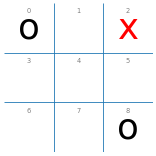


   action  total utility  # of playouts      UCB1
0       1             -4              4  0.517427
1       3             -4              4  0.517427
2       4              6             57  0.507239
3       5             -5              7  0.432781
4       6             -2             24  0.536154
5       7             -4              4  0.517427

Best action: 4


4

In [24]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)


print()
display(UCT_depth1(board))

__Note:__ It looks like random player o is very unlikely to block x and take advantage of the trap by playing the bottom left corner!

## Experiments

### Pure Monte Carlo Search vs. Random

In [25]:
def ucb1_10_player(board, player = 'x'):
    action = UCT_depth1(board, N = 10, player = player)
    return action

def ucb1_100_player(board, player = 'x'):
    action = UCT_depth1(board, N = 100, player = player)
    return action

In [26]:
DEBUG = 0
print("UCB1 (10) vs. random:")
%timeit -n1 -r1 display(play(ucb1_10_player, random_player))

print()
print("random vs. UCB1 (10):")
%timeit -n1 -r1 display(play(random_player, ucb1_10_player))

UCB1 (10) vs. random:


{'x': 91, 'o': 5, 'd': 4}

829 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

random vs. UCB1 (10):


{'x': 20, 'o': 71, 'd': 9}

699 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [27]:
DEBUG = 0
print("UCB1 (100) vs. random:")
%timeit -n 1 -r 1 display(play(ucb1_100_player, random_player))

print()
print("random vs. UCB1 (100):")
%timeit -n 1 -r 1 display(play(random_player, ucb1_100_player))

UCB1 (100) vs. random:


{'x': 98, 'o': 1, 'd': 1}

8.25 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

random vs. UCB1 (100):


{'x': 11, 'o': 80, 'd': 9}

6.54 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [28]:
DEBUG = 0
print("UCB1 (100) vs. UCB1 (10):")
%timeit -n 1 -r 1 display(play(ucb1_100_player, ucb1_10_player))

print()
print("UCB1 (10) vs. UCB1 (100):")
%timeit -n 1 -r 1 display(play(ucb1_10_player, ucb1_100_player))

UCB1 (100) vs. UCB1 (10):


{'x': 85, 'o': 4, 'd': 11}

9.21 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

UCB1 (10) vs. UCB1 (100):


{'x': 35, 'o': 48, 'd': 17}

8.12 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [29]:
import time
from collections import Counter

def pmcs(board, N=100, player='x'):
    """Pure Monte Carlo Search (chia đều playout) để so sánh với UCB1."""
    acts = actions(board)
    n = max(1, math.floor(N / len(acts)))
    ps = {a: np.mean([playout(board, a, player) for _ in range(n)]) for a in acts}
    return max(ps, key=ps.get)

def pmcs100_player(board, player='x'):
    return pmcs(board, N=100, player=player)

def make(xs=(), os_=()):
    b = empty_board()
    for i in xs: b[i] = 'x'
    for i in os_: b[i] = 'o'
    return b

tests = {
    "X sắp thắng (đúng: 8)":   make(xs=[0,4], os_=[1,3]),
    "O sắp thắng (2 mối đe dọa: 2 và 6)": make(xs=[4,8], os_=[0,1,3]),
    "X cần hòa (đúng: 7)":     make(xs=[0,2], os_=[1,4]),
    "Bàn rỗng":                empty_board(),
    "Tình huống bất lợi":      make(xs=[2], os_=[0,8]),
}

In [30]:
DEBUG = 1
print("=== X sắp thắng, N = 100 ===")
UCT_depth1(tests["X sắp thắng (đúng: 8)"], N=100)

print("\n=== X cần hòa, N = 1000 ===")
UCT_depth1(tests["X cần hòa (đúng: 7)"], N=1000)
DEBUG = 0

=== X sắp thắng, N = 100 ===
   action  total utility  # of playouts      UCB1
0       2             21             23  1.545854
1       5              7             11  1.551407
2       6             12             16  1.508714
3       7             17             20  1.528614
4       8             30             30  1.554086

Best action: 8

=== X cần hòa, N = 1000 ===
   action  total utility  # of playouts      UCB1
0       3             -9            106  0.276114
1       5            -13             31  0.248224
2       6            -13             38  0.260859
3       7            119            808  0.278038
4       8            -11             17  0.254427

Best action: 7


### Nhận xét: UCB1 phân bổ playout như thế nào

| Trạng thái | N | Nước tốt nhất | Playout dồn vào nước đó | Nếu chia đều (PMCS) |
|---|---|---|---|---|
| X sắp thắng | 100 | 8 | 30/100 (30%) | 20/100 (20%) |
| X cần hòa | 1000 | 7 | 808/1000 (80,8%) | 200/1000 (20%) |
| Bàn rỗng | 1000 | 4 | 226/1000 (22,6%) | 111/1000 (11,1%) |
| Bàn rỗng | 5000 | 4 | 3405/5000 (68,1%) | 556/5000 (11,1%) |

- UCB1 **dồn playout vào nước có triển vọng** thay vì chia đều. Ở thế "X cần hòa" (N = 1000), nước 7 nhận 808 playout, còn các nước tệ chỉ nhận 17–106 playout.
- Ở thế "X sắp thắng", nước 8 thắng cả 30/30 playout (trung bình +1,0), nên được chọn nhiều nhất.
- Các nước tệ **vẫn được thử một số lần** (ví dụ nước 8 trong thế "X cần hòa" vẫn nhận 17 playout) nhờ phần exploration, nên thuật toán không bỏ sót hoàn toàn.
- Trên bàn rỗng, các nước đều có giá trị gần nhau nên với N = 100 phân bổ còn dàn trải (từ 4 đến 20 playout mỗi ô). Khi N tăng lên 1000 và 5000, ô trung tâm (4) nổi lên rõ rệt vì ước lượng đã đủ chính xác để phân biệt.
- Giá trị UCB1 của các nước ở cuối thuật toán gần bằng nhau (ví dụ 0,278–0,300 ở thế "X cần hòa"). Đây là dấu hiệu thuật toán đã cân bằng: nước tốt có trung bình cao nhưng bonus nhỏ vì được thử nhiều, nước tệ có trung bình thấp nhưng được bù bằng bonus exploration.

In [31]:
DEBUG = 0
REPEAT = 20
for name, b in tests.items():
    print("\n==", name)
    for N in [10, 100, 1000]:
        t0 = time.time()
        u_moves = [UCT_depth1(b, N=N, player='x') for _ in range(REPEAT)]
        t_u = (time.time() - t0) / REPEAT * 1000

        t0 = time.time()
        p_moves = [pmcs(b, N=N, player='x') for _ in range(REPEAT)]
        t_p = (time.time() - t0) / REPEAT * 1000

        print(f"N={N:4d} | UCB1: {dict(Counter(u_moves))} ({t_u:.1f} ms) | "
              f"PMCS: {dict(Counter(p_moves))} ({t_p:.1f} ms)")


== X sắp thắng (đúng: 8)
N=  10 | UCB1: {6: 1, 2: 18, 5: 1} (2.5 ms) | PMCS: {6: 4, 5: 4, 2: 12} (2.0 ms)
N= 100 | UCB1: {8: 20} (12.9 ms) | PMCS: {8: 20} (17.9 ms)
N=1000 | UCB1: {8: 20} (98.9 ms) | PMCS: {8: 20} (176.7 ms)

== O sắp thắng (2 mối đe dọa: 2 và 6)
N=  10 | UCB1: {6: 8, 2: 12} (1.7 ms) | PMCS: {2: 12, 5: 3, 6: 5} (1.1 ms)
N= 100 | UCB1: {6: 17, 2: 3} (13.0 ms) | PMCS: {6: 8, 2: 12} (11.7 ms)
N=1000 | UCB1: {2: 10, 6: 10} (132.3 ms) | PMCS: {6: 10, 2: 10} (121.1 ms)

== X cần hòa (đúng: 7)
N=  10 | UCB1: {7: 8, 3: 5, 5: 5, 8: 1, 6: 1} (1.5 ms) | PMCS: {5: 7, 8: 2, 3: 5, 7: 5, 6: 1} (1.7 ms)
N= 100 | UCB1: {7: 20} (20.5 ms) | PMCS: {7: 17, 5: 2, 3: 1} (63.9 ms)
N=1000 | UCB1: {7: 20} (381.9 ms) | PMCS: {7: 20} (178.5 ms)

== Bàn rỗng
N=  10 | UCB1: {1: 5, 2: 2, 0: 12, 8: 1} (3.6 ms) | PMCS: {0: 9, 5: 1, 2: 2, 1: 7, 3: 1} (3.9 ms)
N= 100 | UCB1: {0: 2, 4: 10, 6: 1, 3: 1, 8: 3, 2: 1, 5: 1, 1: 1} (34.4 ms) | PMCS: {6: 5, 4: 5, 8: 1, 5: 2, 1: 2, 2: 3, 3: 2} (35.9 ms)
N=1000 |

### Nhận xét: độ ổn định của UCB1 so với PMCS

Mỗi cấu hình chạy 20 lần trên cùng một trạng thái. Số trong bảng là số lần chọn đúng nước tốt nhất.

| Trạng thái | N = 10 (UCB1 / PMCS) | N = 100 (UCB1 / PMCS) | N = 1000 (UCB1 / PMCS) |
|---|---|---|---|
| X sắp thắng (đúng: 8) | 0 / 0 | **20** / 20 | **20** / 20 |
| X cần hòa (đúng: 7) | 8 / 5 | **20** / 17 | **20** / 20 |
| Bàn rỗng (ô 4 tốt nhất khi N lớn) | 0 / 0 | 10 / 5 | **20** / 14 |
| Tình huống bất lợi (ô 4) | 10 / 7 | **20** / 18 | **20** / 20 |
| O sắp thắng (2 mối đe dọa: ô 2 hoặc 6) | 12 ô 2, 8 ô 6 | 17 ô 6, 3 ô 2 | 10 ô 2, 10 ô 6 |

**Nhận xét:**

1. **Cùng ngân sách N, UCB1 ổn định hơn PMCS ở N = 100 và N = 1000**: thế "bàn rỗng" chọn ô 4 đạt 10/20 so với 5/20 (N = 100) và 20/20 so với 14/20 (N = 1000); thế "X cần hòa" ở N = 100 đạt 20/20 so với 17/20.
2. **Ở N = 10 cả hai đều không đáng tin**, và UCB1 không hơn PMCS. Thế "X sắp thắng" có 5 nước nên 5 playout đầu dùng để thử mỗi nước một lần, chỉ còn 5 playout để chọn lọc. Khi nhiều nước có cùng số playout, code luôn trả về nước đứng đầu danh sách (`n.index(max(n))`), nên UCB1 chọn ô 2 tới 18/20 lần và ô 0 tới 12/20 lần trên bàn rỗng. Đây là hiệu ứng của cách xử lý hòa chứ không phản ánh nước đi tốt.
3. **N tăng thì quyết định ổn định hơn**: ở N = 1000, bốn trong năm thế cho cùng một nước 20/20 lần; thế còn lại ("O sắp thắng") chia đều 10/10 giữa ô 2 và ô 6 vì X bị hai mối đe dọa cùng lúc, nên hai nước chặn có giá trị gần nhau và việc chia đều là hợp lý.
4. **UCB1 và PMCS cùng chi phí**: thời gian mỗi lần chạy của hai thuật toán cùng bậc độ lớn, vì cùng số playout; phần tính điểm UCB1 chi phí không đáng kể.

In [32]:
b = empty_board()
for N in [10, 100, 1000]:
    t0 = time.time()
    for _ in range(30): UCT_depth1(b, N=N)
    print(f"UCB1 N={N}: {(time.time()-t0)/30*1000:.2f} ms/nước")

UCB1 N=10: 4.32 ms/nước
UCB1 N=100: 42.78 ms/nước
UCB1 N=1000: 427.13 ms/nước


### Nhận xét: thời gian chạy

| N | UCB1 (bàn rỗng) | PMCS (đo ở Bài 5) |
|---|---|---|
| 10 | 4,32 ms | 3,97 ms |
| 100 | 42,78 ms | 41,50 ms |
| 1000 | 427,13 ms | 618,61 ms |

- Thời gian tăng **gần tuyến tính theo N** (khoảng 10 lần mỗi khi N tăng 10 lần), vì chi phí chủ yếu là các playout.
- UCB1 và PMCS có thời gian tương đương ở cùng N. UCB1 không đắt hơn: lợi ích về chất lượng đến từ cách phân bổ playout, không phải từ việc dùng thêm tài nguyên. Chênh lệch ở N = 1000 có thể do tải máy lúc đo.

In [33]:
DEBUG = 0

def ucb1_1000_player(board, player='x'):
    return UCT_depth1(board, N=1000, player=player)

agents = {10: (ucb1_10_player, 1000), 100: (ucb1_100_player, 1000), 1000: (ucb1_1000_player, 100)}

for N, (agent, g) in agents.items():
    t0 = time.time()
    a  = play(agent, random_player, N=g)    # UCB1 là X
    b_ = play(random_player, agent, N=g)    # UCB1 là O
    win  = a['x'] + b_['o']
    lose = a['o'] + b_['x']
    draw = a['d'] + b_['d']
    tot = win + lose + draw
    print(f"UCB1 N={N:4d} | thắng {win/tot:.1%} | hòa {draw/tot:.1%} | "
          f"thua {lose/tot:.1%} | {tot} ván | {time.time()-t0:.1f}s")

# So sánh trực tiếp UCB1(100) với PMCS(100), cùng ngân sách
r1 = play(ucb1_100_player, pmcs100_player, N=300)
r2 = play(pmcs100_player, ucb1_100_player, N=300)
print("UCB1(100) đi trước:", r1)
print("PMCS(100) đi trước:", r2)
print("UCB1 thắng:", r1['x'] + r2['o'], "| PMCS thắng:", r1['o'] + r2['x'], "| hòa:", r1['d'] + r2['d'])

UCB1 N=  10 | thắng 81.0% | hòa 6.3% | thua 12.8% | 2000 ván | 17.0s
UCB1 N= 100 | thắng 91.8% | hòa 4.7% | thua 3.5% | 2000 ván | 153.9s
UCB1 N=1000 | thắng 94.5% | hòa 3.5% | thua 2.0% | 200 ván | 146.1s
UCB1(100) đi trước: {'x': 203, 'o': 11, 'd': 86}
PMCS(100) đi trước: {'x': 163, 'o': 26, 'd': 111}
UCB1 thắng: 229 | PMCS thắng: 174 | hòa: 197


### Kết quả UCB1 đấu random_player và so sánh với PMCS

Mỗi cấu hình đấu cả hai vai: N = 10 và 100 đấu 2000 ván, N = 1000 đấu 200 ván.

| Thuật toán | Thắng | Hòa | Thua | Thời gian/nước |
|---|---|---|---|---|
| UCB1 (N = 10) | 81,0% | 6,3% | 12,8% | 4,3 ms |
| UCB1 (N = 100) | 91,8% | 4,7% | 3,5% | 42,8 ms |
| UCB1 (N = 1000) | 94,5% | 3,5% | 2,0% | 427,1 ms |
| PMCS (N = 10), Bài 5 | 79,3% | 7,4% | 13,2% | 4,0 ms |
| PMCS (N = 100), Bài 5 | 91,1% | 4,3% | 4,5% | 41,5 ms |
| PMCS (N = 1000), Bài 5 | 92,5% | 6,0% | 1,5% | 618,6 ms |

**Đấu trực tiếp UCB1(100) với PMCS(100)** (600 ván, đổi vai):

| | Số ván | Tỷ lệ |
|---|---|---|
| UCB1 thắng | 229 | 38,2% |
| PMCS thắng | 174 | 29,0% |
| Hòa | 197 | 32,8% |

(UCB1 đi trước: 203 thắng, 11 thua, 86 hòa. PMCS đi trước: 163 thắng, 26 thua, 111 hòa.)

**Nhận xét chung:**

1. **UCB1 thắng PMCS khi đấu trực tiếp cùng ngân sách**: trong các ván phân thắng bại (403 ván), UCB1 thắng 229 ván (56,8%). Độ lệch này khoảng 2,7 độ lệch chuẩn so với kỳ vọng 50%, nên khó giải thích bằng ngẫu nhiên.
2. **Khi đấu random_player, chênh lệch giữa UCB1 và PMCS khá nhỏ** (khoảng 1 điểm phần trăm ở N = 100, trong sai số của 2000 ván). Lý do: random_player quá yếu nên cả hai thuật toán đều thắng phần lớn. Đấu trực tiếp mới phân biệt được hai thuật toán.
3. **N tăng thì cả thắng và ổn định tăng**: tỷ lệ thua giảm từ 12,8% xuống 3,5% rồi 2,0%. Từ N = 100 lên 1000 chỉ cải thiện thêm 2,7 điểm phần trăm dù thời gian tăng khoảng 10 lần (lưu ý N = 1000 chỉ có 200 ván nên số liệu kém chính xác hơn).
4. **Lợi thế đi trước**: ở các lần đấu riêng, UCB1(100) đi trước thắng 98/100 nhưng đi sau chỉ thắng 80/100; UCB1(100) đấu UCB1(10) thắng 85 ván khi đi trước, và 48 ván khi đi sau so với 35 ván của UCB1(10) đi trước.

### Trả lời câu hỏi

**UCB1 cân bằng exploration và exploitation như thế nào?**

- Điểm UCB1 của một nước gồm hai phần: `u/n` (exploitation, trung bình hiện tại) và `C·√(ln n_parent / n)` (exploration, bonus lớn khi nước ít được thử).
- Nước có trung bình cao được chọn nhiều hơn, ví dụ nước 7 nhận 808/1000 playout ở thế "X cần hòa". Khi một nước được thử nhiều thì bonus giảm, nhưng nước bị bỏ lâu có bonus tăng theo `ln n_parent`, nên các nước tệ vẫn được kiểm tra lại (nước 8 vẫn nhận 17 playout).
- Tham số `C = √2` điều khiển mức khám phá: C lớn thì gần chia đều như PMCS, C nhỏ thì chỉ khai thác và dễ kẹt ở nước tốt giả.

**Khi số lần mô phỏng tăng, quyết định có ổn định hơn không?**

- **Có.** Ở N = 100, ba trong năm thế đạt 20/20 lần chọn đúng; ở N = 1000, bốn trong năm thế đạt 20/20 (thế còn lại chia 10/10 giữa hai nước chặn có giá trị tương đương). Ví dụ bàn rỗng: 10/20 (N = 100) lên 20/20 (N = 1000) chọn ô 4.
- Ở N = 10 quyết định không ổn định, đặc biệt trên bàn nhiều nước (bàn rỗng), vì sau khi thử mỗi nước một lần gần như không còn ngân sách để chọn lọc.

### Hạn chế

- `UCT_depth1` chỉ có cây sâu 1 và playout ngẫu nhiên, nên vẫn đánh giá nước đi theo giả định đối thủ ngẫu nhiên. MCTS đầy đủ (mở rộng cây nhiều tầng, dùng UCB1 ở mọi tầng) mới khắc phục điều này.
- Hòa giữa các nước luôn chọn nước đứng đầu danh sách, gây thiên lệch ở N nhỏ.